Importing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn import metrics

Data collection and Preprocessing


In [ ]:
# loading the data
exercise=pd.read_csv('/content/exercise_new.csv')


In [ ]:

exercise.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


In [ ]:
#missing values
exercise.isna().sum()

,0
User_ID,0
Gender,0
Age,0
Height,150
Weight,150
Duration,0
Heart_Rate,0
Body_Temp,0


Filling Missing Values

In [ ]:
exercise['Height'] = exercise['Height'].fillna(exercise['Height'].mean())
exercise['Weight'] = exercise['Weight'].fillna(exercise['Weight'].mean())

In [ ]:
exercise.duplicated().sum()

np.int64(0)

In [ ]:
exercise.dtypes

,0
User_ID,int64
Gender,object
Age,int64
Height,float64
Weight,float64
Duration,float64
Heart_Rate,float64
Body_Temp,float64


In [ ]:
exercise['Gender'].value_counts()

,count
Gender,
female,7456
male,7344
\tfemale,29
MALE,28
\tMALE\t,28
MALE\t,26
FEMALE\t,24
FEMALE,22
\tFEMALE\t,22


In [ ]:
#stripping,lowercase
exercise['Gender'] = exercise['Gender'].astype(str).str.strip().str.lower()

In [ ]:
#ensure they are standardized
print(exercise['Gender'].value_counts())

Gender
female    7553
male      7447
Name: count, dtype: int64


In [ ]:
calories=pd.read_csv('/content/drive/MyDrive/archive (1)/calories.csv')

In [ ]:
calories.head()

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


Combining two DataFrames

In [ ]:
#combining the two dataset
df=pd.concat([exercise, calories['Calories']], axis=1)

In [ ]:
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [ ]:
df.shape

(15000, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB


Data Analysis


In [ ]:
df.describe()

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.476633,74.989764,15.530600,95.518533,40.025453,89.539533
std,2.872851e+06,16.980264,14.184145,14.973057,8.319203,9.583328,0.779230,62.456978
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,1.499728e+07,39.000000,174.476633,74.000000,16.000000,96.000000,40.200000,79.000000
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


Data Visualization

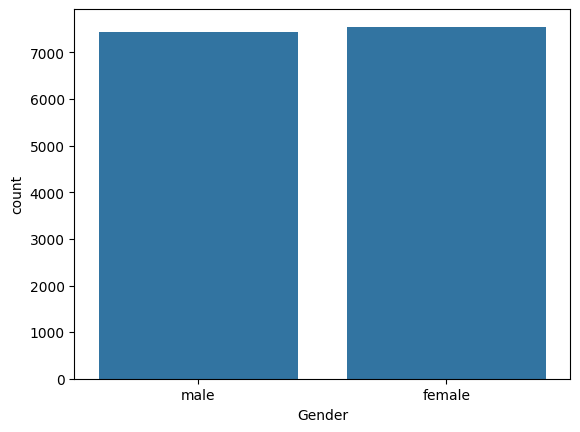

In [ ]:
# plotting the gender column in count plot
sns.countplot(x='Gender', data=df)
plt.show()

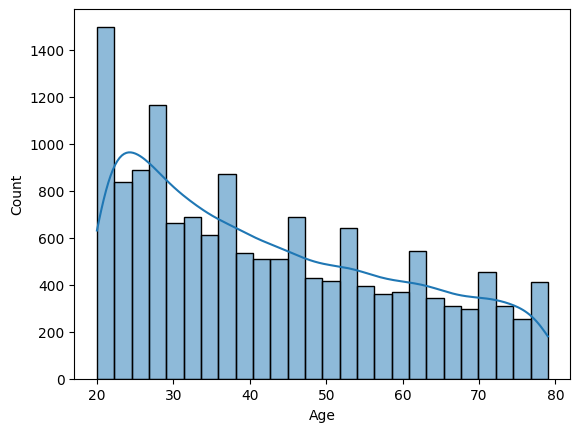

In [ ]:
sns.histplot(df['Age'], kde=True)
plt.show()

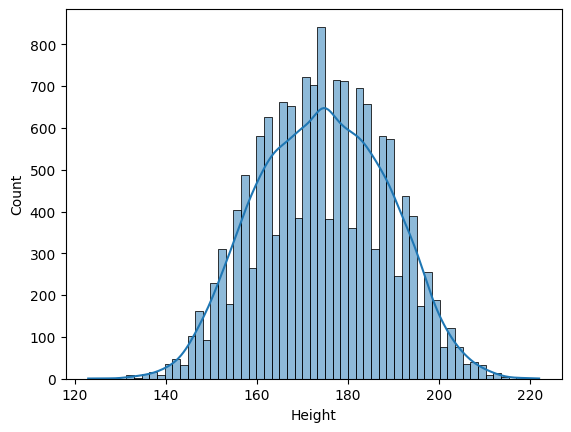

In [ ]:
sns.histplot(df['Height'], kde=True)
plt.show()

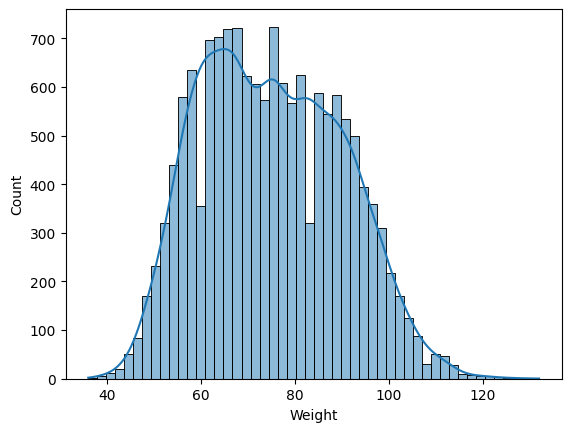

In [ ]:
sns.histplot(df['Weight'], kde=True)
plt.show()

Converting the text data to numerical values

Finding The Correlation in Dataset
1.Positive Correlation
2.Negative Correlation


In [ ]:
gender_mapping = {'male': 0, 'female': 1}
df['Gender'] = df['Gender'].map(gender_mapping)

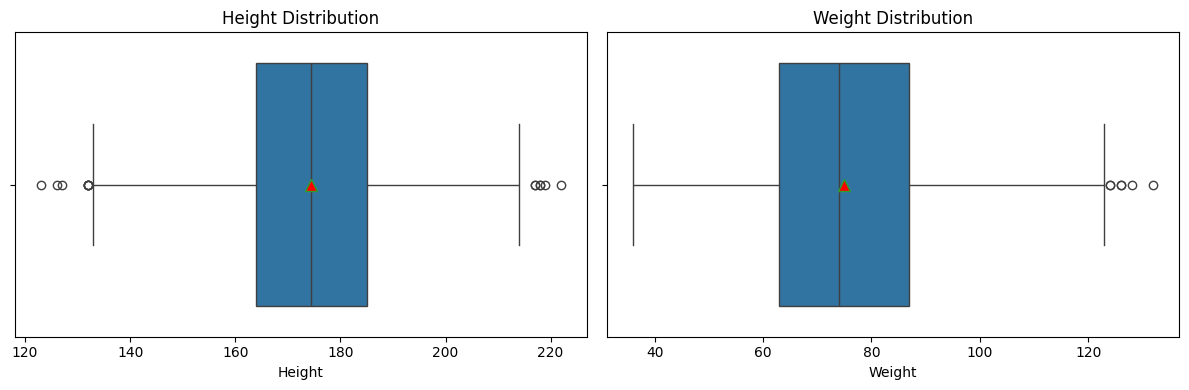

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(['Height', 'Weight']):
    sns.boxplot(x=df[col], ax=axes[i], showmeans=True,
                meanprops={"marker": "^", "markerfacecolor": "red", "markersize": "8"})
    axes[i].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()

<Axes: >

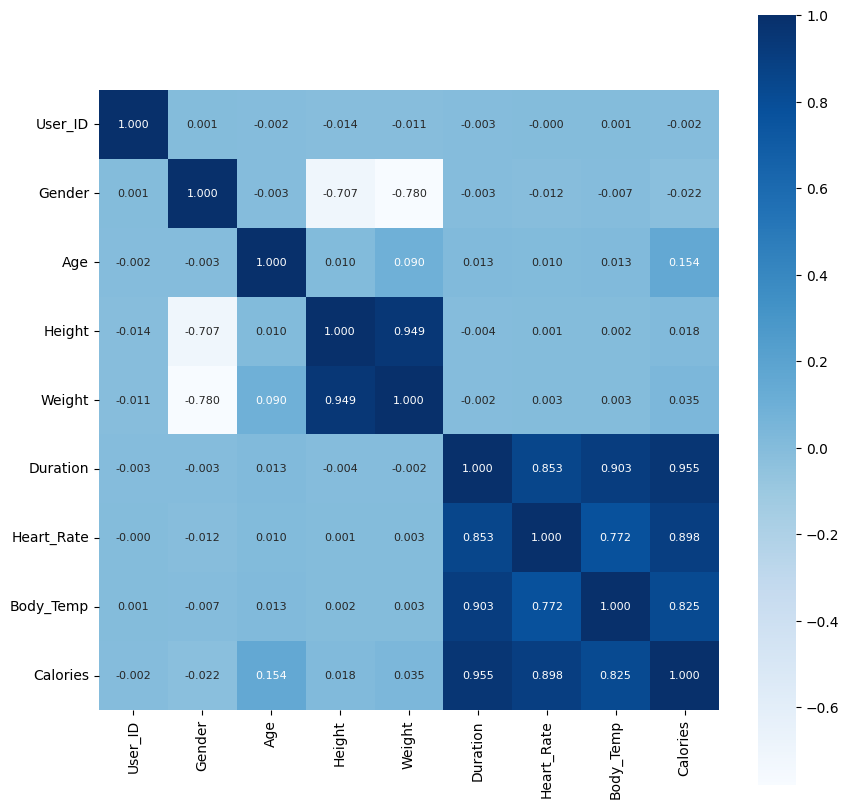

In [ ]:
correlation=df.corr()

plt.figure(figsize=(10,10))
sns.heatmap(correlation, cbar=True, square=True, fmt='.3f', annot=True, annot_kws={'size':8}, cmap='Blues')

Separating features and Target

In [ ]:
x=df.drop(columns=['User_ID','Calories'], axis=1)
y=df['Calories']

In [ ]:
x

,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,0,68,190.0,94.0,29.0,105.0,40.8
1,1,20,166.0,60.0,14.0,94.0,40.3
2,0,69,179.0,79.0,5.0,88.0,38.7
3,1,34,179.0,71.0,13.0,100.0,40.5
4,1,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...
14995,1,20,193.0,86.0,11.0,92.0,40.4
14996,1,27,165.0,65.0,6.0,85.0,39.2
14997,1,43,159.0,58.0,16.0,90.0,40.1
14998,0,78,193.0,97.0,2.0,84.0,38.3


In [ ]:
y

,Calories
0,231.0
1,66.0
2,26.0
3,71.0
4,35.0
...,...
14995,45.0
14996,23.0
14997,75.0
14998,11.0


Splitting the data into training data and Test data

In [ ]:
x_train, x_test,y_train,y_test=train_test_split(x,y,test_size=0.2, random_state=2)

In [ ]:
print(x.shape,x_train.shape,x_test.shape)

(15000, 7) (12000, 7) (3000, 7)


Model Training

In [ ]:
models={
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

for name, model in models.items():
    model.fit(x_train, y_train)

    pred_test = model.predict(x_test)


    print(name)
    print("MAE:", metrics.mean_absolute_error(y_test, pred_test))
    print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, pred_test)))
    print("R2 Score:", metrics.r2_score(y_test, pred_test))
    print("----------------------------")

Linear Regression
MAE: 8.385246460774997
RMSE: 11.401786447054716
R2 Score: 0.9669010203265667
----------------------------
Decision Tree
MAE: 3.4426666666666668
RMSE: 5.284442575459907
R2 Score: 0.9928900398434373
----------------------------
Random Forest
MAE: 1.6854133333333332
RMSE: 2.6286820144957312
R2 Score: 0.9982406797213613
----------------------------
XGBoost
MAE: 1.5040542811354
RMSE: 2.21326288630577
R2 Score: 0.9987528037275828
----------------------------


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

param_grid = {
    'n_estimators': [100, 300, 500, 700],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

xgb_model = xgb.XGBRegressor(random_state=42)
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=10,
    scoring='neg_mean_squared_error',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(x_train, y_train)
print("\nBest Parameters found:")
print(random_search.best_params_)

best_xgb = random_search.best_estimator_
tuned_pred = best_xgb.predict(x_test)

print("\nTuned XGBoost Performance:")
print("MAE:", metrics.mean_absolute_error(y_test, tuned_pred))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, tuned_pred)))
print("R2 Score:", metrics.r2_score(y_test, tuned_pred))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters found:
{'subsample': 0.7, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 1.0}

Tuned XGBoost Performance:
MAE: 1.0620571893354256
RMSE: 1.5205348701520809
R2 Score: 0.999411344007386


In [ ]:
sample=x_test[0:1]

In [ ]:
predicted = models['XGBoost'].predict(sample)

In [ ]:
actual_predicted = y_test[0:1]
print("model predicted:", predicted)
print("actual predicted:", actual_predicted.values)


model predicted: [124.84359]
actual predicted: [127.]


In [ ]:
#saving model
models['XGBoost'].save_model('xgboost_model.json')

In [ ]:
df.iloc[1:2]

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
1,14861698,1,20,166.0,60.0,14.0,94.0,40.3,66.0


In [ ]:
from sklearn.metrics import r2_score


y_train_pred = best_xgb.predict(x_train)

y_test_pred = best_xgb.predict(x_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R2 Score:", train_r2)
print("Testing R2 Score:", test_r2)


Training R2 Score: 0.99984913788011
Testing R2 Score: 0.999411344007386
